# Random Forest para clasificar dígitos escritos (`load_digits` de scikit-learn)

**Objetivo:** diseñar e implementar un clasificador Random Forest para el dataset *digits* de scikit-learn y encontrar el **mínimo número de árboles**, del **menor tamaño posible**, que ofrezca el mejor rendimiento **sin over-fitting**.

**Condiciones del enunciado:**
- División 80 % entrenamiento / 20 % prueba.
- Entrenamiento con validación cruzada K-fold, K = 4.
- Estrategia de poda basada en `ccp_alpha` (poda por costo-complejidad).

## 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

SEMILLA = 42  # para que los resultados sean reproducibles

## 2. Cargar y dividir el dataset en 80% para entrenamiento y 20% para prueba.  

- `test_size=0.2` → 80 % entrenamiento, 20 % prueba, como pide el enunciado.
- `stratify=y` → cada clase conserva la misma proporción en entrenamiento y en prueba.

In [2]:
X, y = load_digits(return_X_y=True) # importar dataset digits de sklearn.datasets

# imágenes y respuestas para entrenar y probar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)

# shape: filas / columnas
print("Dataset completo:", X.shape)
print("Datos de Entrenamiento: ", X_train.shape)
print("Datos de Prueba:", X_test.shape)

Dataset completo: (1797, 64)
Datos de Entrenamiento:  (1437, 64)
Datos de Prueba: (360, 64)


Algunos ejemplos del dataset: cada imagen es de 8×8 píxeles y su título es el dígito que representa.

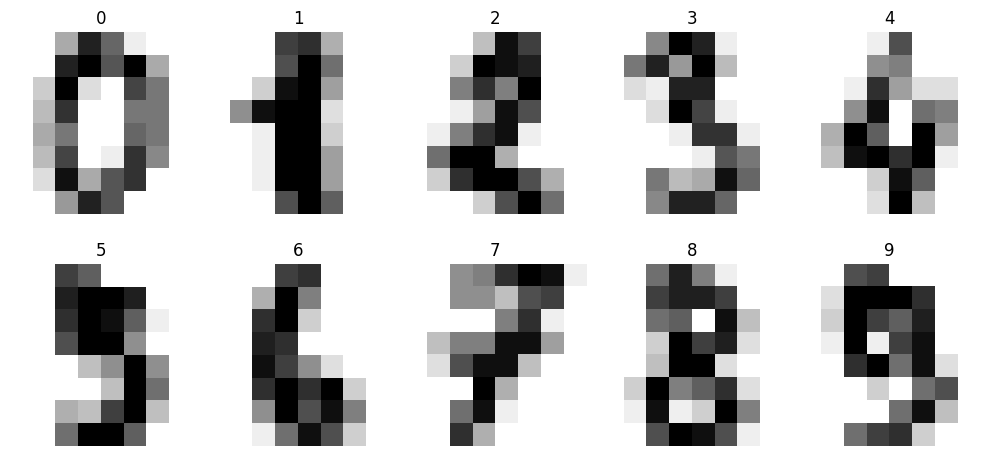

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, imagen, etiqueta in zip(axes.ravel(), X[:10], y[:10]):
    ax.imshow(imagen.reshape(8, 8), cmap="gray_r")  # cada fila de 64 valores vuelve a ser una imagen 8×8
    ax.set_title(etiqueta)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Estrategia de poda: `ccp_alpha` (poda por costo-complejidad)

En el repositorio https://github.com/eduardozurek/ia/blob/main/_007_aprendizaje_supervisado/_007_arboles_de_decision/_007_01_ccp_alpha_DecisionTreeClassifier.ipynb tenemos una explicación del parámetro ccp_alpha

Cada árbol del bosque se poda con *Minimal Cost-Complexity Pruning*. SK-learn minimiza internamente, para cada árbol $T$:

$$R_\alpha(T)=R(T)+\alpha\,|T_L|$$

donde $R(T)$ es la impureza total de las hojas, $|T_L|$ el número de hojas y $\alpha$ = `ccp_alpha`.

- Con `ccp_alpha = 0` no hay poda: el árbol crece hasta tener hojas puras (árbol grande, riesgo de over-fitting).
- A mayor sea `ccp_alpha`, más se van descartando los subárboles que no aporten, lo cual resulta en **árboles más pequeños**.
- Si `ccp_alpha` es demasiado grande, el árbol queda sin casi ramas, lo cual lleva al under-fitting.

Entonces, `ccp_alpha` define cuánto tiene que aportar una rama para que valga la pena conservarla.

Es una **poda posterior**: primero se construye el árbol y luego se podan los subárboles con menor $\alpha_{\text{eff}}$. No se usan restricciones de crecimiento previo (`max_depth`, `min_samples_leaf`, etc.) para que el tamaño de los árboles lo controle un único parámetro.

**Valores candidatos de `ccp_alpha`:** en lugar de probar valores arbitrarios, se obtienen con `cost_complexity_pruning_path` sobre un árbol entrenado con los datos de entrenamiento. Esto da los valores de $\alpha$ en los que el árbol cambia de tamaño. Se toman 12 valores espaciados a lo largo de ese camino (se excluye el último, que deja solo la raíz).

*Nota:* en Random Forest cada árbol se entrena con una muestra bootstrap distinta, así que estos valores son una referencia de la escala de $\alpha$ para este problema, no los valores exactos de cada árbol.

In [4]:
arbol = DecisionTreeClassifier(random_state=SEMILLA) # crear árbol de decisión
camino = arbol.cost_complexity_pruning_path(X_train, y_train) # lista de valores de ccp_alpha de las que menos a las que más aportan, para podar después.
alphas = camino.ccp_alphas[:-1]  # se quita el último valor porque ese poda todo el árbol

print("Número de alphas en el camino de poda:", len(alphas))

indices = np.unique(np.linspace(0, len(alphas) - 1, 12).astype(int))
ccp_alphas = alphas[indices]
print("Candidatos de ccp_alpha:", ", ".join(f"{a:.5f}" for a in ccp_alphas))

Número de alphas en el camino de poda: 122
Candidatos de ccp_alpha: 0.00000, 0.00070, 0.00104, 0.00111, 0.00136, 0.00186, 0.00244, 0.00277, 0.00373, 0.00638, 0.01382, 0.05829


### Árbol base (punto de partida)

Antes de construir el bosque, se entrena **un solo árbol sin poda** para ver el problema que se quiere resolver. Se mide de dos formas:
- Con **validación cruzada K-fold (K = 4)** sobre el conjunto de entrenamiento, como pide el enunciado.
- Con el **conjunto de prueba**, solo como referencia (no se usa para elegir nada).

Si la exactitud de entrenamiento es mucho mayor que la de validación o prueba, el árbol está memorizando: **over-fitting**.

In [5]:
arbol.fit(X_train, y_train) # datos del arbol despues de entrenarlo

acc_train_base = arbol.score(X_train, y_train) 
acc_test_base = arbol.score(X_test, y_test)

print(f"Exactitud del árbol base en entrenamiento: {acc_train_base:.4f}")
print(f"Exactitud del árbol base en prueba:        {acc_test_base:.4f}")
print(f"Brecha entre entrenamiento y prueba:       {acc_train_base - acc_test_base:.4f}")
print(f"Profundidad del árbol:                     {arbol.get_depth()}")
print(f"Número de hojas del árbol:                 {arbol.get_n_leaves()}")

Exactitud del árbol base en entrenamiento: 1.0000
Exactitud del árbol base en prueba:        0.8250
Brecha entre entrenamiento y prueba:       0.1750
Profundidad del árbol:                     14
Número de hojas del árbol:                 142


In [6]:
kfold = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEMILLA)  # K-fold = 4, se reutiliza en la sección 4

res_base = cross_validate(arbol, X_train, y_train, cv=kfold, return_train_score=True, scoring="accuracy")

for i, (tr, va) in enumerate(zip(res_base["train_score"], res_base["test_score"]), start=1):
    print(f"Fold {i}: entrenamiento {tr:.4f} | validación {va:.4f}")

print()
print(f"Entrenamiento promedio: {res_base['train_score'].mean():.4f}")
print(f"Validación promedio:    {res_base['test_score'].mean():.4f} ± {res_base['test_score'].std():.4f}")
print(f"Brecha promedio:        {res_base['train_score'].mean() - res_base['test_score'].mean():.4f}")

Fold 1: entrenamiento 1.0000 | validación 0.8389
Fold 2: entrenamiento 1.0000 | validación 0.8607
Fold 3: entrenamiento 1.0000 | validación 0.8524
Fold 4: entrenamiento 1.0000 | validación 0.8468

Entrenamiento promedio: 1.0000
Validación promedio:    0.8497 ± 0.0080
Brecha promedio:        0.1503


## 4. Búsqueda con validación cruzada K-fold (K = 4)

Se evalúan todas las combinaciones de:
- `n_estimators` (número de árboles): de 1 a 300.
- `ccp_alpha` (tamaño de los árboles): los 12 candidatos anteriores.

Se usa `StratifiedKFold(n_splits=4)`: el conjunto de entrenamiento se divide en 4 partes; en cada iteración se entrena con 3 y se valida con la restante. Se guarda la exactitud (*accuracy*) de **entrenamiento** y de **validación** (`return_train_score=True`) para poder medir el over-fitting.

Los demás parámetros del Random Forest quedan en su valor por defecto (`criterion="gini"`, `bootstrap=True`, `max_features="sqrt"`).



In [ ]:
parametros = {
    "n_estimators": [1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150, 200, 300],
    "ccp_alpha": ccp_alphas,
}

busqueda = GridSearchCV(
    RandomForestClassifier(random_state=SEMILLA),
    param_grid=parametros,
    cv=kfold,
    scoring="accuracy",
    return_train_score=True,
    refit=False, 
    n_jobs=-1,
)
busqueda.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ccp_alpha': array([0. ..., 0.05829204]), 'n_estimators': [1, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is di

## 5. Resultados de la validación cruzada y over-fitting

Para cada combinación se calcula:
- `acc_validacion`: exactitud promedio en los 4 folds de validación.
- `acc_entrenamiento`: exactitud promedio sobre los folds de entrenamiento.
- `brecha = acc_entrenamiento − acc_validacion`: si es grande, el modelo memoriza los datos de entrenamiento y no generaliza (**over-fitting**).

In [8]:
res = pd.DataFrame(busqueda.cv_results_)
res = pd.DataFrame({
    "n_estimators": res["param_n_estimators"].astype(int),
    "ccp_alpha": res["param_ccp_alpha"].astype(float),
    "acc_entrenamiento": res["mean_train_score"],
    "acc_validacion": res["mean_test_score"],
    "std_validacion": res["std_test_score"],
})
res["brecha"] = res["acc_entrenamiento"] - res["acc_validacion"]

print("Exactitud de validación (filas: ccp_alpha, columnas: n_estimators)")
tabla = res.pivot(index="ccp_alpha", columns="n_estimators", values="acc_validacion")
tabla.index = np.round(tabla.index, 5)
tabla.round(3)

Exactitud de validación (filas: ccp_alpha, columnas: n_estimators)


n_estimators,1,5,10,20,30,40,50,60,70,80,90,100,150,200,300
ccp_alpha,,,,,,,,,,,,,,,
0.00000,0.773,0.900,0.941,0.964,0.965,0.967,0.967,0.969,0.969,0.969,0.971,0.972,0.971,0.976,0.973
0.00070,0.773,0.901,0.942,0.962,0.965,0.968,0.966,0.967,0.969,0.969,0.971,0.972,0.971,0.976,0.974
0.00104,0.776,0.902,0.940,0.960,0.968,0.967,0.966,0.967,0.969,0.970,0.970,0.972,0.969,0.972,0.972
0.00111,0.777,0.901,0.941,0.960,0.968,0.967,0.966,0.967,0.969,0.969,0.970,0.972,0.969,0.972,0.971
0.00136,0.777,0.904,0.939,0.962,0.968,0.965,0.967,0.965,0.968,0.969,0.969,0.971,0.969,0.972,0.971
0.00186,0.784,0.905,0.937,0.958,0.959,0.961,0.964,0.965,0.966,0.968,0.967,0.970,0.971,0.973,0.973
0.00244,0.781,0.903,0.940,0.958,0.961,0.958,0.962,0.964,0.965,0.965,0.967,0.970,0.970,0.971,0.969
0.00277,0.779,0.897,0.937,0.956,0.960,0.961,0.964,0.963,0.964,0.964,0.966,0.968,0.966,0.970,0.967
0.00373,0.766,0.889,0.930,0.947,0.955,0.956,0.960,0.961,0.960,0.962,0.960,0.960,0.960,0.963,0.960


In [9]:
print("Brecha entrenamiento − validación (filas: ccp_alpha, columnas: n_estimators)")
tabla_brecha = res.pivot(index="ccp_alpha", columns="n_estimators", values="brecha")
tabla_brecha.index = np.round(tabla_brecha.index, 5)
tabla_brecha.round(3)

Brecha entrenamiento − validación (filas: ccp_alpha, columnas: n_estimators)


n_estimators,1,5,10,20,30,40,50,60,70,80,90,100,150,200,300
ccp_alpha,,,,,,,,,,,,,,,
0.00000,0.137,0.093,0.058,0.036,0.035,0.033,0.033,0.031,0.031,0.031,0.029,0.028,0.029,0.024,0.027
0.00070,0.137,0.092,0.058,0.038,0.035,0.032,0.034,0.033,0.031,0.031,0.029,0.028,0.029,0.024,0.026
0.00104,0.127,0.089,0.058,0.039,0.032,0.033,0.034,0.033,0.031,0.030,0.030,0.028,0.031,0.028,0.028
0.00111,0.126,0.090,0.058,0.039,0.032,0.033,0.034,0.033,0.031,0.031,0.030,0.028,0.031,0.028,0.029
0.00136,0.121,0.085,0.059,0.038,0.032,0.035,0.033,0.035,0.032,0.031,0.031,0.029,0.031,0.028,0.029
0.00186,0.090,0.079,0.056,0.040,0.040,0.039,0.036,0.034,0.034,0.032,0.032,0.029,0.028,0.027,0.027
0.00244,0.083,0.078,0.052,0.040,0.037,0.041,0.037,0.036,0.035,0.035,0.033,0.029,0.029,0.028,0.031
0.00277,0.075,0.081,0.053,0.039,0.036,0.037,0.034,0.035,0.035,0.035,0.033,0.031,0.033,0.029,0.032
0.00373,0.068,0.075,0.051,0.044,0.038,0.037,0.034,0.034,0.036,0.034,0.036,0.036,0.036,0.034,0.036


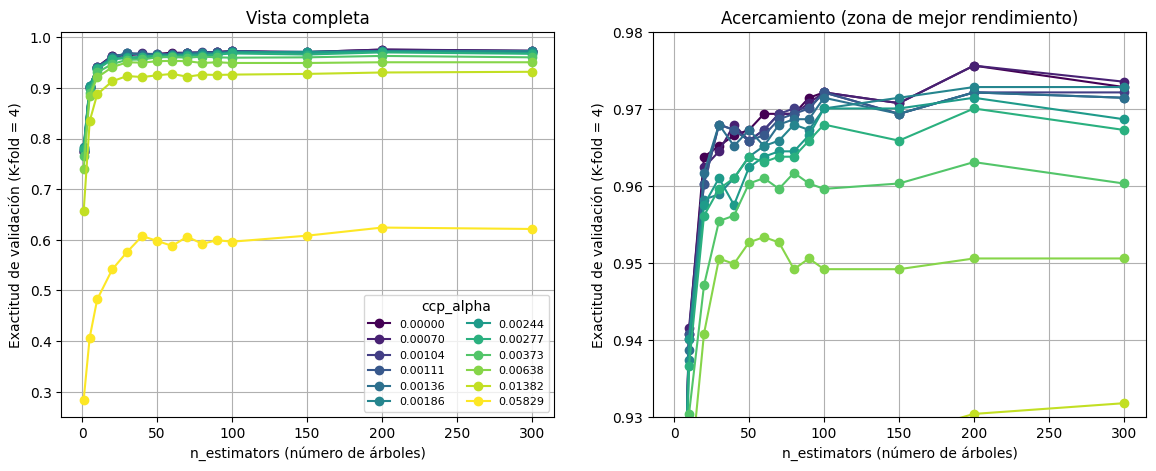

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores = plt.cm.viridis(np.linspace(0, 1, len(ccp_alphas)))
for ax, titulo in zip(axes, ["Vista completa", "Acercamiento (zona de mejor rendimiento)"]):
    for color, (a, grupo) in zip(colores, res.groupby("ccp_alpha")):
        ax.plot(grupo["n_estimators"], grupo["acc_validacion"], marker="o", color=color, label=f"{a:.5f}")
    ax.set_xlabel("n_estimators (número de árboles)")
    ax.set_ylabel("Exactitud de validación (K-fold = 4)")
    ax.set_title(titulo)
    ax.grid(True)
axes[1].set_ylim(0.93, 0.98)
axes[0].legend(title="ccp_alpha", fontsize=8, ncol=2)
plt.show()

## 6. Criterio de selección: mínimo número de árboles, del menor tamaño, sin over-fitting

El enunciado pide el **mínimo número de árboles**, **del menor tamaño posible**, con los **mejores indicadores de rendimiento** y **sin over-fitting**. Se aplica en este orden:

1. **Mejor rendimiento:** se identifica la combinación con mayor exactitud de validación. Se aceptan como "equivalentes" las combinaciones cuya exactitud está a no más de **una desviación estándar** (entre folds) de la mejor. Diferencias menores que esa variación no son significativas: dependen de cómo se partieron los folds.
2. **Sin over-fitting:** se descartan las combinaciones con brecha entrenamiento − validación mayor a 0.05 (5 puntos porcentuales).
3. **Mínimo número de árboles:** entre las que quedan, se elige el menor `n_estimators`.
4. **Menor tamaño de árbol:** con ese número de árboles, se elige el mayor `ccp_alpha` (más poda → árboles más pequeños).

In [11]:
MAX_BRECHA = 0.05

mejor = res.loc[res["acc_validacion"].idxmax()]
umbral = mejor["acc_validacion"] - mejor["std_validacion"]

print(f"Mejor combinación: n_estimators={int(mejor['n_estimators'])}, "
      f"ccp_alpha={mejor['ccp_alpha']:.5f}, "
      f"acc_validacion={mejor['acc_validacion']:.4f} ± {mejor['std_validacion']:.4f}")
print(f"Umbral de exactitud aceptable: {umbral:.4f}")

candidatos = res[(res["acc_validacion"] >= umbral) & (res["brecha"] <= MAX_BRECHA)]
candidatos = candidatos.sort_values(["n_estimators", "ccp_alpha"], ascending=[True, False])

elegido = candidatos.iloc[0]
N_ARBOLES = int(elegido["n_estimators"])
ALPHA = float(elegido["ccp_alpha"])

print(f"\nCombinación elegida: n_estimators={N_ARBOLES}, ccp_alpha={ALPHA:.5f}")
print(f"acc_validacion={elegido['acc_validacion']:.4f}, brecha={elegido['brecha']:.4f}")

candidatos.head(10).round(4)

Mejor combinación: n_estimators=200, ccp_alpha=0.00000, acc_validacion=0.9756 ± 0.0050
Umbral de exactitud aceptable: 0.9707

Combinación elegida: n_estimators=90, ccp_alpha=0.00070
acc_validacion=0.9708, brecha=0.0292


,n_estimators,ccp_alpha,acc_entrenamiento,acc_validacion,std_validacion,brecha
25,90,0.0007,1.0000,0.9708,0.0046,0.0292
10,90,0.0000,1.0000,0.9715,0.0036,0.0285
71,100,0.0014,1.0000,0.9715,0.0041,0.0285
56,100,0.0011,1.0000,0.9722,0.0034,0.0278
41,100,0.0010,1.0000,0.9722,0.0034,0.0278
26,100,0.0007,1.0000,0.9722,0.0028,0.0278
11,100,0.0000,1.0000,0.9722,0.0028,0.0278
87,150,0.0019,0.9998,0.9715,0.0030,0.0283
27,150,0.0007,1.0000,0.9708,0.0024,0.0292
12,150,0.0000,1.0000,0.9708,0.0024,0.0292


## 7. Efecto de la poda en el tamaño de los árboles

Para mostrar cómo `ccp_alpha` reduce el tamaño de los árboles, se entrena un bosque con el número de árboles elegido para cada `ccp_alpha` candidato y se mide el promedio de **nodos** y de **profundidad** de sus árboles, junto con la exactitud de validación obtenida en la sección 4.

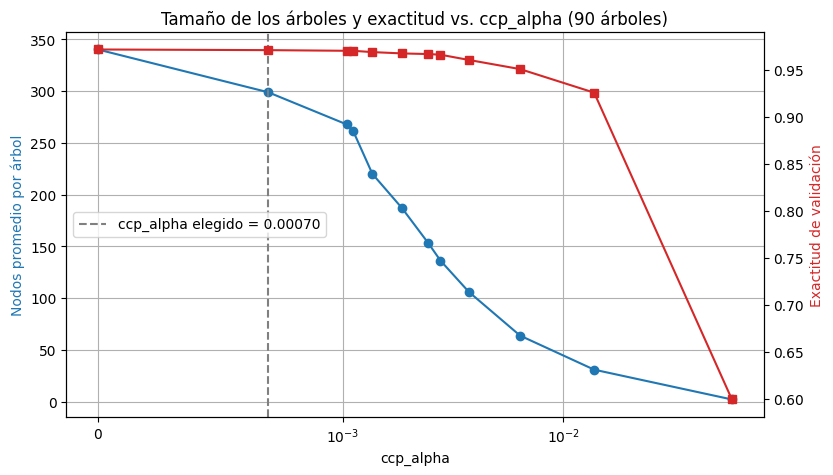

,ccp_alpha,nodos_promedio,profundidad_promedio,acc_validacion
0,0.0000,340.1333,13.2889,0.9715
1,0.0007,298.8000,12.7444,0.9708
2,0.0010,267.6889,12.3667,0.9701
3,0.0011,261.6000,12.3333,0.9701
4,0.0014,219.9778,11.8444,0.9687
5,0.0019,187.0000,11.4778,0.9673
6,0.0024,153.0667,10.7889,0.9666
7,0.0028,136.2667,10.4667,0.9659
8,0.0037,106.0222,9.7444,0.9603
9,0.0064,63.7778,8.2333,0.9506


In [12]:
filas = []
for a in ccp_alphas:
    rf = RandomForestClassifier(n_estimators=N_ARBOLES, ccp_alpha=a, random_state=SEMILLA)
    rf.fit(X_train, y_train)
    acc_val = res[(res["n_estimators"] == N_ARBOLES) & (res["ccp_alpha"] == a)]["acc_validacion"].iloc[0]
    filas.append({
        "ccp_alpha": a,
        "nodos_promedio": np.mean([t.tree_.node_count for t in rf.estimators_]),
        "profundidad_promedio": np.mean([t.get_depth() for t in rf.estimators_]),
        "acc_validacion": acc_val,
    })
tamanos = pd.DataFrame(filas)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(tamanos["ccp_alpha"], tamanos["nodos_promedio"], marker="o", color="tab:blue")
ax1.set_xscale("symlog", linthresh=1e-3)
ax1.set_xlabel("ccp_alpha")
ax1.set_ylabel("Nodos promedio por árbol", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(tamanos["ccp_alpha"], tamanos["acc_validacion"], marker="s", color="tab:red")
ax2.set_ylabel("Exactitud de validación", color="tab:red")
ax1.axvline(ALPHA, color="gray", linestyle="--", label=f"ccp_alpha elegido = {ALPHA:.5f}")
ax1.legend(loc="center left")
ax1.set_title(f"Tamaño de los árboles y exactitud vs. ccp_alpha ({N_ARBOLES} árboles)")
ax1.grid(True)
plt.show()

tamanos.round(4)

## 8. Modelo final y evaluación en el conjunto de prueba

Se entrena el Random Forest con la combinación elegida usando todo el conjunto de entrenamiento (80 %) y se evalúa **por primera vez** con el conjunto de prueba (20 %). Si la exactitud de prueba es parecida a la de validación, el modelo generaliza y no hay over-fitting.

In [13]:
modelo = RandomForestClassifier(n_estimators=N_ARBOLES, ccp_alpha=ALPHA, random_state=SEMILLA)
modelo.fit(X_train, y_train)

acc_train = accuracy_score(y_train, modelo.predict(X_train))
y_pred = modelo.predict(X_test)
acc_test = accuracy_score(y_test, y_pred)

print(f"Árboles: {N_ARBOLES} | ccp_alpha: {ALPHA:.5f}")
print(f"Nodos promedio por árbol: {np.mean([t.tree_.node_count for t in modelo.estimators_]):.1f}")
print(f"Profundidad promedio:     {np.mean([t.get_depth() for t in modelo.estimators_]):.1f}")
print()
print(f"Exactitud entrenamiento:        {acc_train:.4f}")
print(f"Exactitud validación (K-fold):  {elegido['acc_validacion']:.4f}")
print(f"Exactitud prueba:               {acc_test:.4f}")
print()
print(classification_report(y_test, y_pred, digits=4))

Árboles: 90 | ccp_alpha: 0.00070
Nodos promedio por árbol: 298.8
Profundidad promedio:     12.7

Exactitud entrenamiento:        1.0000
Exactitud validación (K-fold):  0.9708
Exactitud prueba:               0.9611

              precision    recall  f1-score   support

           0     0.9722    0.9722    0.9722        36
           1     0.8974    0.9722    0.9333        36
           2     1.0000    0.9714    0.9855        35
           3     0.9730    0.9730    0.9730        37
           4     0.9722    0.9722    0.9722        36
           5     0.9737    1.0000    0.9867        37
           6     1.0000    0.9722    0.9859        36
           7     0.9231    1.0000    0.9600        36
           8     0.9375    0.8571    0.8955        35
           9     0.9706    0.9167    0.9429        36

    accuracy                         0.9611       360
   macro avg     0.9620    0.9607    0.9607       360
weighted avg     0.9620    0.9611    0.9609       360



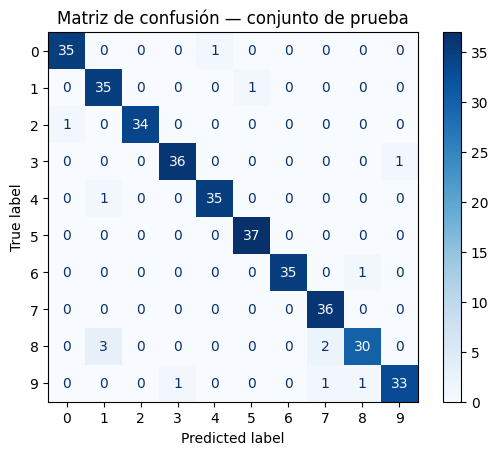

In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión — conjunto de prueba")
plt.show()

## 9. Conclusiones

- **Árbol base:** un solo árbol sin poda acierta el 100 % en entrenamiento pero solo el 85 % en validación (brecha ≈ 0.15) y el 82.5 % en prueba: memoriza los datos (over-fitting). Este es el problema que el Random Forest con poda resuelve.
- **Estrategia de poda:** se usó poda posterior por costo-complejidad (`ccp_alpha`) en cada árbol del bosque, con valores candidatos tomados del camino de poda (`cost_complexity_pruning_path`). Al aumentar `ccp_alpha` los árboles pasan de unos 340 nodos (sin poda) a muy pocos nodos, y la exactitud cae cuando la poda es excesiva (under-fitting).
- **Número de árboles:** la exactitud de validación sube rápido hasta unos 20–30 árboles y luego se estabiliza alrededor de 0.97; agregar más árboles casi no mejora el rendimiento.
- **Combinación elegida:** **90 árboles con `ccp_alpha` ≈ 0.0007** (≈ 299 nodos y profundidad ≈ 12.7 en promedio, frente a ≈ 340 nodos sin poda). Es el menor número de árboles cuya exactitud de validación (0.9708) está dentro de una desviación estándar de la mejor (0.9756 con 200 árboles), y con ese número de árboles es la mayor poda que se mantiene dentro de ese margen. Podar más reduce la exactitud por debajo del umbral.
- **Over-fitting:** la brecha entrenamiento − validación es ≈ 0.03 (menor que el límite de 0.05). La exactitud de entrenamiento es 1.0 porque cada árbol de un Random Forest se ajusta a su propia muestra bootstrap; lo que importa es que el rendimiento en datos no vistos se mantenga alto: exactitud de prueba **0.9611**, cercana a la de validación, con F1 macro ≈ 0.96. El modelo generaliza.
- La clase con más errores es el **8** (recall ≈ 0.86), que se confunde principalmente con el 1 (3 casos) y el 7 (2 casos), según la matriz de confusión.